[Part 1](13a_Stochastic_Deterministic_Trends.ipynb) of this chapter set up the regression with ARIMA errors, and used the simplest predictor of all: the time index $t$. This second part uses two richer kinds of predictors.

**Fourier terms** (Chapter 7) describe a seasonal pattern of any length with a few sine and cosine pairs. With ARMA errors added for the short-term dynamics, the model is called **dynamic harmonic regression**. It is the method of choice for long seasonal periods, such as daily data with an annual cycle, where the seasonal ARIMA models of Chapter 12 become impractical. **Lagged predictors** let a predictor act over several periods, as advertising does on sales.

# Learning objectives

By the end of this lecture you should be able to

1. explain why seasonal dummies and SARIMA become impractical for long seasonal periods, and model the seasonality with Fourier terms and ARMA errors instead;
2. choose the number of Fourier pairs $K$ and the order of the ARMA errors by AICc, and check the choice on held-out data;
3. combine Fourier terms of several periods with other predictors, as for daily electricity demand with a weekly and an annual cycle, and explain what the ARMA errors add to the forecasts;
4. write down a regression with **lagged predictors**, compare lag lengths fairly, and forecast with assumed future values of the predictor.

# Setup

Modules and functions used in this lecture.

| Module | Used for |
|---|---|
| `numpy` | `log`, `exp`, `sqrt`, `maximum`, `tile` |
| `pandas` | `read_csv`, `groupby`, `pivot_table`, `resample`, `shift`, `date_range` |
| `matplotlib.pyplot` | `subplots`, `plot`, `stem`, `fill_between` |
| `itertools` | `product` -- all combinations of the candidate orders |
| `time` | `perf_counter` -- timing the order searches |
| `statsmodels.api` | `OLS`, `add_constant` -- the same regressions without ARMA errors, for comparison |
| `statsmodels.tsa.arima.model` | `ARIMA` with `exog` (Part 1) |
| `statsmodels.tsa.statespace.sarimax` | `SARIMAX` -- only to show the size of a SARIMA model with $s = 365$ |
| `statsmodels.tsa.stattools` | `adfuller`, `kpss` (Chapter 5), `ccf` (Chapter 9) |
| `statsmodels.graphics.tsaplots` | `plot_acf` |
| `statsmodels.stats.diagnostic` | `acorr_ljungbox` (Chapter 7) |

In [1]:
import time
import warnings
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss, ccf
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

# Expected noise we do not want in the output:
#  - ARIMA warns when the optimizer stops before full convergence, and when it
#    replaces unusable starting values by zeros;
#  - KPSS warns when its statistic falls outside its table of p-values (Chapter 5);
#  - statsmodels 0.15 announces a future change to the return type of adfuller.
from statsmodels.tools.sm_exceptions import ConvergenceWarning, EstimationWarning, InterpolationWarning
warnings.simplefilter("ignore", ConvergenceWarning)
warnings.simplefilter("ignore", EstimationWarning)
warnings.simplefilter("ignore", InterpolationWarning)
warnings.simplefilter("ignore", FutureWarning)

Self-defined functions carried over from earlier chapters: the run-sequence plot (Chapter 4), the MSE (Chapter 6), `fourier_terms` (Chapter 7), the MAPE (Chapter 12), and from Part 1, `forecast_with_interval` with its `exog` and `back` arguments, `regression_residuals`, `residual_check` and `select_arma`.

In [2]:
def run_sequence_plot(y, x=None, title="", xlabel="time", ylabel="value",
                      ax=None, figsize=(9, 3), color="blue", **kwargs):
    "Plot a series against time and return the axes."
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    if x is None:
        x = getattr(y, "index", np.arange(len(y)))
    ax.plot(x, y, color=color, lw=1, **kwargs)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(alpha=0.3)
    return ax


def mse(observations, estimates):
    "Mean squared error between two equal-length sequences."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    if observations.shape != estimates.shape:
        raise ValueError(f"shape mismatch: {observations.shape} vs {estimates.shape}")
    return np.mean((observations - estimates) ** 2)


def fourier_terms(t, period, K, prefix="f"):
    "Return a DataFrame of K sine/cosine pairs for the given seasonal period."
    t = np.asarray(t, dtype=float)
    cols = {}
    for k in range(1, K + 1):
        cols[f"{prefix}sin{k}"] = np.sin(2 * np.pi * k * t / period)
        cols[f"{prefix}cos{k}"] = np.cos(2 * np.pi * k * t / period)
    out = pd.DataFrame(cols)
    return out.loc[:, out.std() > 1e-12]        # drop terms that are identically zero


def mape(observations, estimates):
    "Mean absolute percentage error, in percent."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    return 100 * np.mean(np.abs((observations - estimates) / observations))


def forecast_with_interval(ax, fit, steps, x, color="red", label="forecast", exog=None, back=None):
    "Draw the forecast of a fitted model and its 95% prediction interval; return the forecast."
    fc = fit.get_forecast(steps, exog=exog)
    mean, ci = np.asarray(fc.predicted_mean), np.asarray(fc.conf_int(alpha=0.05))
    if back is not None:                      # undo a transformation, e.g. np.exp after a log
        mean, ci = back(mean), back(ci)
    ax.plot(x, mean, color=color, ls="--", lw=1.5, label=label)
    ax.fill_between(x, ci[:, 0], ci[:, 1], color=color, alpha=0.15)
    return mean


def regression_residuals(fit, y, X):
    "Regression errors eta_t = y_t - intercept - X_t beta of a regression with ARIMA errors."
    X = pd.DataFrame(X)
    return y - fit.params.get("const", 0.0) - X @ fit.params[X.columns]


def residual_check(fit, y, X, lags=10, title=""):
    "Time plots and ACFs of the regression and innovation residuals, with Ljung-Box tests."
    burn = fit.loglikelihood_burn                  # first residuals, dominated by the initialization
    eta = regression_residuals(fit, y, X).iloc[burn:]
    if fit.model.k_diff:                           # with d >= 1 the level of eta is not identified
        eta = eta - eta.mean()
    eps = fit.resid.iloc[burn:]
    arma_df = sum(name.startswith(("ar.", "ma.")) for name in fit.param_names)

    fig, axes = plt.subplots(2, 2, figsize=(13, 5.5))
    for row, (series, name) in enumerate([(eta, r"regression residuals $\hat\eta_t$"),
                                          (eps, r"innovation residuals $\hat\varepsilon_t$")]):
        run_sequence_plot(series, title=name, ylabel="", ax=axes[row, 0])
        axes[row, 0].axhline(0, color="black", lw=0.8)
        axes[row, 0].tick_params(axis="x", labelrotation=30)
        plot_acf(series, lags=lags, ax=axes[row, 1], title=f"ACF of the {name}")
        axes[row, 1].set_xlabel("lag k")
        axes[row, 1].grid(alpha=0.3)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

    for series, name, df in [(eta, "regression residuals", 0), (eps, "innovation residuals", arma_df)]:
        lb = acorr_ljungbox(series, lags=[lags], model_df=df)
        print(f"Ljung-Box, {name} (lag {lags}, model_df = {df}): "
              f"Q = {lb['lb_stat'].iloc[0]:.2f}, p = {lb['lb_pvalue'].iloc[0]:.3g}")


def select_arma(y, exog=None, d=0, trend="c", max_p=2, max_q=2):
    "Fit ARIMA(p, d, q) errors for all p <= max_p and q <= max_q; information criteria, best AICc first."
    rows = []
    for p, q in product(range(max_p + 1), range(max_q + 1)):
        fit = ARIMA(y, exog=exog, order=(p, d, q), trend=trend).fit()
        rows.append({"order": (p, d, q), "AIC": fit.aic, "AICc": fit.aicc, "BIC": fit.bic})
    return pd.DataFrame(rows).sort_values("AICc").reset_index(drop=True)

# Dynamic harmonic regression

When the seasonal period is long, a dynamic regression with Fourier terms is often better than the other models we have considered. Daily data can have an annual cycle of $m = 365.25$ days, weekly data an annual cycle of $m \approx 52.18$ weeks, and half-hourly data several cycles, the shortest of which, the day, is already $m = 48$.

The seasonal models we know were designed for short periods such as $m = 12$ for monthly or $m = 4$ for quarterly data.

- **Seasonal dummies** (Chapter 7) need $m - 1$ coefficients: 364 for daily data.
- **Holt-Winters** smoothing (Chapter 6) must estimate $m - 1$ initial seasonal values, which becomes almost impossible for large $m$.
- **SARIMA** (Chapter 12) loses a full period of data to the seasonal difference, and its seasonal terms make the model large. We will measure how large below.
- None of them handles a period that is not a whole number, such as 365.25 days or 52.18 weeks.

For such series, we prefer a **harmonic regression**: the seasonal pattern is modelled by the Fourier terms of Chapter 7,

$$y_t = \beta_0 + \sum_{k=1}^{K}\left[\alpha_k \sin\!\Bigl(\frac{2\pi k t}{m}\Bigr) + \gamma_k \cos\!\Bigl(\frac{2\pi k t}{m}\Bigr)\right] + \eta_t ,$$

and the short-term dynamics by an ARMA error $\eta_t$, or an ARIMA error if the series also needs differencing. The approach has four advantages:

- it allows a seasonal period of any length, including a non-integer one;
- for data with several seasonal periods, Fourier terms of each period can be included;
- the smoothness of the seasonal pattern is controlled by $K$, the number of sine and cosine pairs: the smaller $K$, the smoother the pattern;
- the short-term dynamics are easily handled with a simple ARMA error.

The only real disadvantage, compared with SARIMA, is that the seasonal pattern is **fixed**: it is not allowed to change over time. In practice, seasonality is usually remarkably constant, so this is a problem mainly for long series.

## Example: eating-out expenditure in Australia

The file `data/aus_retail.csv` holds the monthly turnover, in millions of Australian dollars, of 20 retail industries in each Australian state. We add up the states for the industry "Cafes, restaurants and takeaway food services" and keep 2004 to 2018. With $m = 12$, this is not a long seasonal period, and SARIMA would work too; we start here because the effect of $K$ is easy to see on monthly data, and turn to a long period afterwards.

180 months, Jan 2004 - Dec 2018


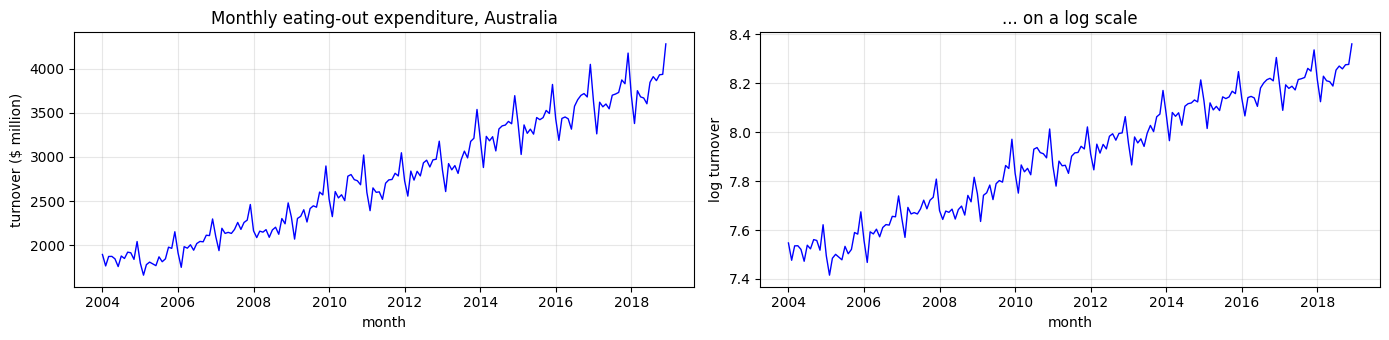

In [3]:
retail = pd.read_csv("data/aus_retail.csv", parse_dates=["Month"])
cafe = (retail.loc[retail["Industry"] == "Cafes, restaurants and takeaway food services"]
        .groupby("Month")["Turnover"].sum()
        .loc["2004":"2018"].asfreq("MS"))
print(f"{len(cafe)} months, {cafe.index[0]:%b %Y} - {cafe.index[-1]:%b %Y}")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
run_sequence_plot(cafe, title="Monthly eating-out expenditure, Australia", xlabel="month",
                  ylabel="turnover ($ million)", ax=axes[0])
run_sequence_plot(np.log(cafe), title="... on a log scale", xlabel="month",
                  ylabel="log turnover", ax=axes[1])
plt.tight_layout(); plt.show()

The expenditure grows from 1.9 to 4.3 billion dollars a month, with a peak every December, and the seasonal swings grow with the level. As in Chapter 8, we take logs, which makes the seasonal swings roughly constant in size. Forecasts of the log are transformed back with `back=np.exp`, which gives the median of the forecast distribution (Chapter 8).

We keep the last two years, 2017 and 2018, as a test set, and choose the model on 2004 to 2016.

### Does the series need differencing?

The log turnover trends upwards, and we can model the trend deterministically or stochastically (Part 1). A common rule, used by automatic ARIMA procedures, is to apply the KPSS test (Chapter 5) to the residuals of the regression estimated by OLS, without ARMA errors. If KPSS rejects stationarity, the errors are differenced, and the test is repeated on the differences. We use the most flexible seasonal pattern, $K = 6$ Fourier pairs.

In [4]:
y_cafe = np.log(cafe)
t_cafe = np.arange(1, len(y_cafe) + 1)


def cafe_design(t, K, index):
    "Time index t (for the drift) and K Fourier pairs of period 12."
    return pd.concat([pd.DataFrame({"t": t}), fourier_terms(t, period=12, K=K)], axis=1).set_axis(index)


design = {K: cafe_design(t_cafe, K, y_cafe.index) for K in range(1, 7)}

train_end, test_start = "2016-12-01", "2017-01-01"
y_train, y_test = y_cafe[:train_end], y_cafe[test_start:]

ols = sm.OLS(y_train, sm.add_constant(design[6][:train_end].drop(columns="t"))).fit()
for name, series in [("OLS residuals", ols.resid), ("differenced OLS residuals", ols.resid.diff().dropna())]:
    stat, p, _, crit = kpss(series, regression="c", nlags="auto")
    print(f"KPSS on the {name:25s}: statistic = {stat:.3f}, 5% critical value = {crit['5%']:.3f}, p = {p:.2f}")

KPSS on the OLS residuals            : statistic = 1.804, 5% critical value = 0.463, p = 0.01
KPSS on the differenced OLS residuals: statistic = 0.081, 5% critical value = 0.463, p = 0.10


KPSS rejects stationarity for the residuals ($p \le 0.01$, the edge of its table) but not for their differences ($p \ge 0.10$). So the errors get one difference, $d = 1$. For the average growth, we also include the time index $t$ as a predictor: with $d = 1$, this is the stochastic trend of Part 1, and the coefficient of $t$ is the drift. The model is Fourier terms for the seasonality plus a random walk with drift and ARMA errors.

### Choosing $K$

For each $K$ from 1 to 6, `select_arma` chooses the ARMA$(p, q)$ part of the ARIMA$(p, 1, q)$ errors by AICc, with $p, q \le 3$. $K = 6$ is the largest possible value for $m = 12$: as Chapter 7 showed, six pairs (eleven terms, since $\sin(\pi t)$ is identically zero) span the same space as seasonal dummies. All 96 models have the same $d$ and the same data, so their AICc values can be compared across $K$.

time required: 29 s


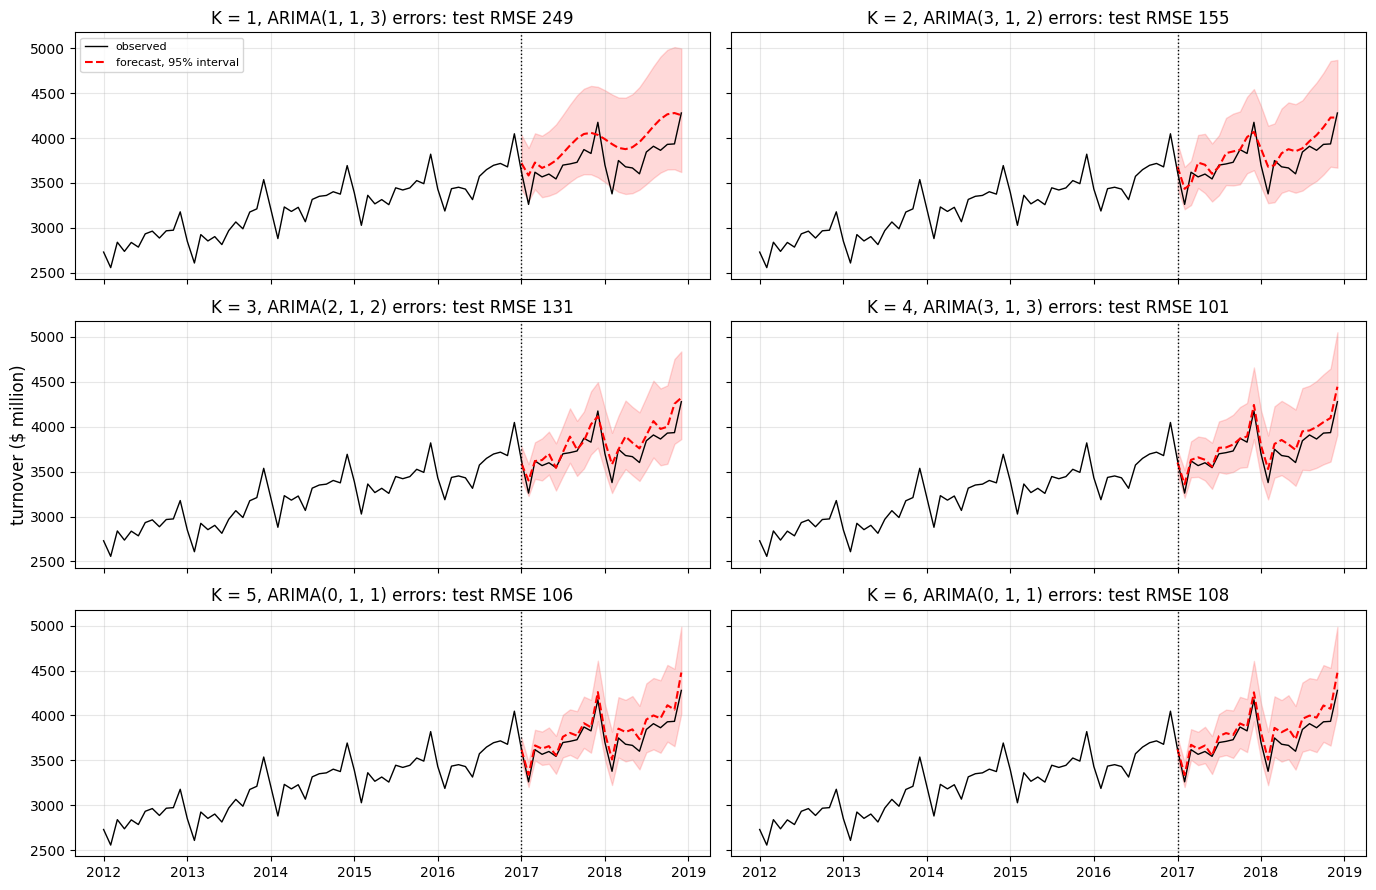

,ARIMA errors,AICc,test RMSE,test MAPE (%)
1,"(1, 1, 3)",-528.06,248.89,6.00
2,"(3, 1, 2)",-575.81,155.32,3.59
3,"(2, 1, 2)",-656.27,131.39,2.77
4,"(3, 1, 3)",-745.36,101.08,2.33
5,"(0, 1, 1)",-774.88,106.33,2.48
6,"(0, 1, 1)",-774.12,108.39,2.54
seasonal naive,-,NaN,202.30,5.05


In [5]:
start = time.perf_counter()
chosen = {K: select_arma(y_train, exog=X[:train_end], d=1, trend="n", max_p=3, max_q=3).iloc[0]
          for K, X in design.items()}
print(f"time required: {time.perf_counter() - start:.0f} s")

cafe_test = cafe[test_start:]
fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex=True, sharey=True)
rows = {}
for ax, (K, best) in zip(axes.flatten(), chosen.items()):
    X = design[K]
    fit = ARIMA(y_train, exog=X[:train_end], order=best["order"]).fit()
    ax.plot(cafe["2012":], color="black", lw=1, label="observed")
    pred = forecast_with_interval(ax, fit, len(y_test), y_test.index, exog=X[test_start:], back=np.exp,
                                  label="forecast, 95% interval")
    rows[K] = {"ARIMA errors": best["order"], "AICc": best["AICc"],
               "test RMSE": np.sqrt(mse(cafe_test, pred)), "test MAPE (%)": mape(cafe_test, pred)}
    ax.axvline(y_test.index[0], color="black", ls=":", lw=1)
    ax.set(title=f"K = {K}, ARIMA{best['order']} errors: test RMSE {rows[K]['test RMSE']:.0f}")
    ax.grid(alpha=0.3)
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.supylabel("turnover ($ million)")
plt.tight_layout(); plt.show()

snaive = np.tile(cafe["2016"].to_numpy(), 2)           # seasonal naive: repeat 2016 twice
rows["seasonal naive"] = {"ARIMA errors": "-", "AICc": np.nan, "test RMSE": np.sqrt(mse(cafe_test, snaive)),
                          "test MAPE (%)": mape(cafe_test, snaive)}
pd.DataFrame(rows).T.astype({"AICc": float, "test RMSE": float, "test MAPE (%)": float}).round(2)

- **AICc falls as $K$ grows**, steeply up to $K = 4$ and less from $K = 4$ to $K = 5$. $K = 5$ has the lowest AICc, and $K = 6$ is less than one point behind: the two are practically equivalent.
- **The ARMA errors get simpler as $K$ grows.** With one to four Fourier pairs, the errors need four to six ARMA coefficients; with five or six pairs, a single MA coefficient is enough. The part of the seasonal pattern that the Fourier terms miss ends up in the errors, and an ARMA model reproduces a regular annual shape only clumsily.
- **On the test years**, $K = 4$, 5 and 6 are practically equal (RMSE 101 to 108 million dollars, MAPE 2.3% to 2.5%), and all three are about twice as accurate as seasonal naive. With $K \le 3$ the forecast misses part of the seasonal shape: with $K = 1$ the seasonal pattern is a single sine wave, which cannot produce the December peak. One 24-month test period cannot separate $K = 4$ from $K = 6$ (Chapter 11), and AICc's choice, $K = 5$, is among the best.

We refit the selected model, $K = 5$ with ARIMA(0,1,1) errors and drift, on all the data from 2004 to 2018, and forecast the next two years. Since the model is fitted to the log turnover, the drift is a growth rate.

In [6]:
K_cafe = 5
X_cafe = design[K_cafe]
fit_cafe = ARIMA(y_cafe, exog=X_cafe, order=(0, 1, 1)).fit()
print(fit_cafe.summary().tables[1])
print(f"drift: {fit_cafe.params['t']:.4f} per month, i.e. {100 * (np.exp(12 * fit_cafe.params['t']) - 1):.1f}% growth per year")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
t              0.0039      0.001      4.715      0.000       0.002       0.006
fsin1         -0.0281      0.003    -10.998      0.000      -0.033      -0.023
fcos1          0.0241      0.003      9.136      0.000       0.019       0.029
fsin2         -0.0146      0.002     -8.655      0.000      -0.018      -0.011
fcos2          0.0165      0.002      9.469      0.000       0.013       0.020
fsin3         -0.0070      0.001     -4.945      0.000      -0.010      -0.004
fcos3          0.0355      0.002     22.854      0.000       0.032       0.039
fsin4          0.0131      0.001      9.293      0.000       0.010       0.016
fcos4          0.0157      0.001     11.030      0.000       0.013       0.018
fsin5          0.0181      0.001     13.410      0.000       0.015       0.021
fcos5          0.0184      0.001     12.638      0.0

The individual Fourier coefficients have no simple meaning; together they describe the seasonal shape. The MA coefficient is clearly significant, and the drift, the coefficient of $t$, corresponds to a growth of about 5% per year. The residual check is on the log scale.

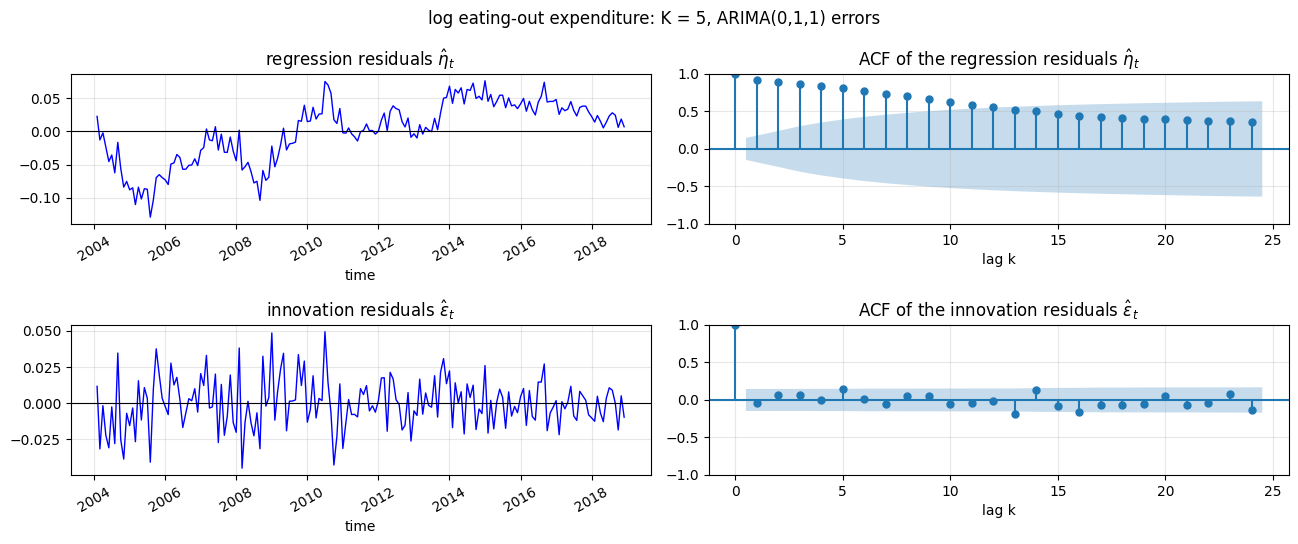

Ljung-Box, regression residuals (lag 24, model_df = 0): Q = 1718.47, p = 0
Ljung-Box, innovation residuals (lag 24, model_df = 1): Q = 35.38, p = 0.0476


In [7]:
residual_check(fit_cafe, y_cafe, X_cafe, lags=24, title="log eating-out expenditure: K = 5, ARIMA(0,1,1) errors")

With $d = 1$, the level of $\hat\eta_t$ is not identified (the intercept drops out), so `residual_check` centres it. The regression residuals are the deviations from the drift line and the seasonal pattern. They wander slowly, as the random walk that $d = 1$ allows, and their ACF decays slowly. The innovation residuals show no structure in time. Two of their autocorrelations, at lags 13 and 16, reach the edge of the band, and the Ljung-Box test over two years of lags gives $p = 0.048$, a borderline rejection at the 5% level. Lag 12, where a seasonal pattern missed by the Fourier terms would show up, is close to zero, and neither lag 13 nor lag 16 has an obvious interpretation, so we keep the model. Now the forecasts.

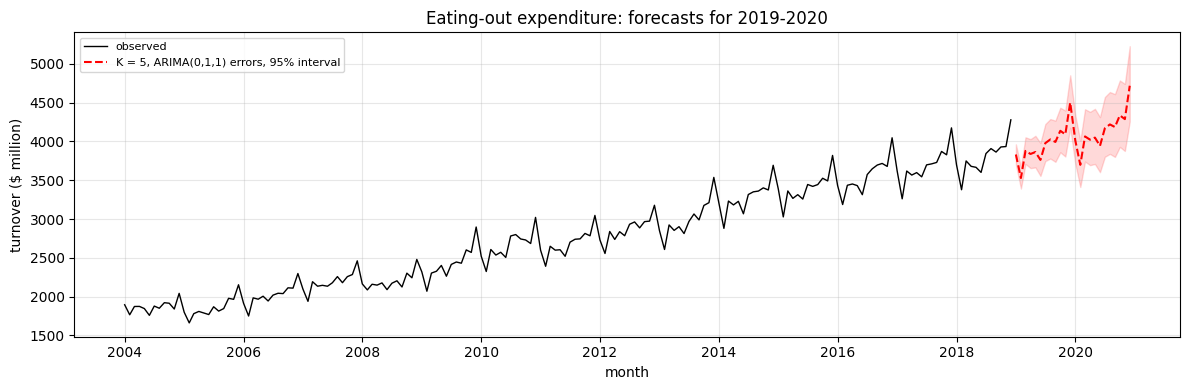

In [8]:
H = 24
idx_future = pd.date_range(cafe.index[-1] + pd.DateOffset(months=1), periods=H, freq="MS")
X_future = cafe_design(np.arange(len(y_cafe) + 1, len(y_cafe) + H + 1), K_cafe, idx_future)

_, ax = plt.subplots(figsize=(12, 4))
ax.plot(cafe, color="black", lw=1, label="observed")
forecast_with_interval(ax, fit_cafe, H, idx_future, exog=X_future, back=np.exp,
                       label="K = 5, ARIMA(0,1,1) errors, 95% interval")
ax.set(title="Eating-out expenditure: forecasts for 2019-2020", xlabel="month", ylabel="turnover ($ million)")
ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

The future predictors are the continued time index $t$ and the Fourier terms evaluated at it. The forecasts continue the growth with the fixed seasonal shape, December peak included. The interval widens with the horizon, as for every model with $d = 1$, and it is wider above the forecast than below it: the back-transformation turns a symmetric interval for the log into an asymmetric one for the turnover.

## Long seasonal periods: daily electricity demand

Daily electricity demand in Victoria, the data of Chapters 7 and 8, has two seasonal periods: a **weekly** cycle, $m = 7$, and an **annual** cycle, $m = 365.25$. We rebuild the daily table of Chapter 7 and the degree days of Chapter 8: cooling degrees $\max(T - 20, 0)$ and heating degrees $\max(18 - T, 0)$, where $T$ is the daily maximum temperature.

In [9]:
raw = pd.read_csv("data/vic_elec.csv")
raw["ds"] = pd.to_datetime(raw["ds"], format="%m/%d/%Y %H:%M")
wide = raw.pivot_table(index="ds", columns="unique_id", values="y")
holiday = raw.loc[raw["unique_id"] == "Demand"].set_index("ds")["Holiday"]

elec = pd.DataFrame({
    "Demand":      wide["Demand"].resample("D").sum() / 1000,   # MW per half hour -> GWh per day
    "Temperature": wide["Temperature"].resample("D").max(),     # daily maximum
}).asfreq("D")
elec["Holiday"] = holiday.resample("D").max().astype(float)
elec["Cooling"] = np.maximum(elec["Temperature"] - 20, 0)      # cooling degree days
elec["Heating"] = np.maximum(18 - elec["Temperature"], 0)      # heating degree days
print(f"{len(elec)} days, {elec.index[0]:%d %b %Y} - {elec.index[-1]:%d %b %Y}")

1096 days, 01 Jan 2012 - 31 Dec 2014


### Why not SARIMA?

We build, without fitting, a SARIMA$(1, 0, 1) \times (0, 1, 1)_s$ model for the daily demand, once with the weekly period and once with a 365-day year. `statsmodels` stores a SARIMA model in *state-space form*: at every time step, the Kalman filter updates a vector of unobserved states, whose length `k_states` grows with $s$.

In [10]:
for s in [7, 365]:
    model = SARIMAX(elec["Demand"], order=(1, 0, 1), seasonal_order=(0, 1, 1, s))
    print(f"s = {s:3d}: {model.k_states:3d} states, first {model.loglikelihood_burn:3d} observations "
          f"spent on the seasonal difference ({model.loglikelihood_burn / len(elec):.0%} of the data)")

s =   7:  16 states, first   7 observations spent on the seasonal difference (1% of the data)
s = 365: 732 states, first 365 observations spent on the seasonal difference (33% of the data)


With $s = 365$, the filter must update a vector of 732 states at each of the 1,096 days, a third of the data is spent on the seasonal difference, and the model pretends that every year has 365 days. With Fourier terms, the annual cycle costs $2K$ coefficients and no data at all.

### The model

We combine Fourier terms of both periods with the calendar and weather predictors:

$$\text{Demand}_t = \beta_0 + \underbrace{\sum_{k=1}^{K_a}\Bigl[\alpha_k \sin\tfrac{2\pi k t}{365.25} + \gamma_k \cos\tfrac{2\pi k t}{365.25}\Bigr]}_{\text{annual cycle}} + \underbrace{\sum_{k=1}^{3}\Bigl[\alpha'_k \sin\tfrac{2\pi k t}{7} + \gamma'_k \cos\tfrac{2\pi k t}{7}\Bigr]}_{\text{weekly cycle}} + \beta_1\,\text{Holiday}_t + \beta_2\,\text{Cooling}_t + \beta_3\,\text{Heating}_t + \eta_t ,$$

where $t$ counts the days from 1 January 2012 and $\eta_t$ is an ARMA process. Three weekly pairs are the maximum for $m = 7$: they reproduce any pattern over the seven days of the week, like six day-of-week dummies. The number of annual pairs $K_a$ is to be chosen.

We fit on 1 January 2012 to 31 October 2014 and keep November and December 2014 as a test set. Searching all combinations of $K_a$ and the ARMA order would take several minutes, so we search in two steps: first the ARMA order with a moderate $K_a = 3$, then $K_a$ from 1 to 10 with that order.

In [11]:
t_elec = np.arange(len(elec))
weekly = fourier_terms(t_elec, period=7, K=3, prefix="w").set_axis(elec.index)
other = elec[["Holiday", "Cooling", "Heating"]]


def elec_design(K_a):
    "Annual Fourier pairs, weekly Fourier pairs, holiday dummy and degree days."
    annual = fourier_terms(t_elec, period=365.25, K=K_a, prefix="a").set_axis(elec.index)
    return pd.concat([annual, weekly, other], axis=1)


elec_end, elec_test = "2014-10-31", "2014-11-01"
demand = elec["Demand"]
d_train, d_test = demand[:elec_end], demand[elec_test:]

start = time.perf_counter()
grid = select_arma(d_train, exog=elec_design(3)[:elec_end], d=0, trend="c")
print(f"step 1, ARMA order with K_a = 3 ({time.perf_counter() - start:.0f} s):")
print(grid.head(3).round(1).to_string(), "\n")

order_elec = grid.loc[0, "order"]
start = time.perf_counter()
by_K = pd.DataFrame([{"K_a": K_a, **{k: v for k, v in zip(["AICc", "BIC"], [fit.aicc, fit.bic])}}
                     for K_a in range(1, 11)
                     for fit in [ARIMA(d_train, exog=elec_design(K_a)[:elec_end], order=order_elec,
                                       trend="c").fit()]]).set_index("K_a")
print(f"step 2, K_a with ARMA{order_elec} errors ({time.perf_counter() - start:.0f} s):")
print(by_K.round(1).T.to_string())

step 1, ARMA order with K_a = 3 (14 s):
       order     AIC    AICc     BIC
0  (2, 0, 1)  7191.4  7192.2  7290.3
1  (2, 0, 2)  7193.3  7194.2  7297.0
2  (1, 0, 2)  7197.5  7198.4  7296.4 



step 2, K_a with ARMA(2, 0, 1) errors (21 s):
K_a       1       2       3       4       5       6       7       8       9       10
AICc  7221.0  7192.2  7192.2  7186.8  7190.3  7193.8  7193.5  7194.9  7196.2  7199.6
BIC   7299.6  7280.5  7290.3  7294.6  7307.8  7320.9  7330.3  7341.4  7352.2  7365.2


ARMA(2,1) errors come first in step 1, and with them AICc is lowest at $K_a = 4$ in step 2. $K_a = 2$ and 3 are about five points behind, and BIC, with its heavier penalty, would choose $K_a = 2$. Rerunning step 1 with $K_a = 4$ selects ARMA(2,1) again. We fit the final model, and the same regression by OLS for comparison.

In [12]:
K_a = 4
X_elec = elec_design(K_a)
X_train, X_test = X_elec[:elec_end], X_elec[elec_test:]
fit_elec = ARIMA(d_train, exog=X_train, order=order_elec, trend="c").fit()
ols_elec = sm.OLS(d_train, sm.add_constant(X_train)).fit()

show = ["Holiday", "Cooling", "Heating"]
pd.DataFrame({"dynamic regression": fit_elec.params[show], "std error": fit_elec.bse[show],
              "OLS": ols_elec.params[show], "OLS std error": ols_elec.bse[show]}).round(3)

,dynamic regression,std error,OLS,OLS std error
Holiday,-30.041,0.929,-35.432,2.124
Cooling,2.146,0.052,3.085,0.097
Heating,2.438,0.303,4.608,0.289


A public holiday lowers demand by about 30 GWh; each degree of maximum temperature above 20 °C adds about 2.1 GWh, and each degree below 18 °C about 2.4 GWh. The OLS estimates of the same coefficients are noticeably larger, and for the holiday and cooling effects their standard errors are about twice as large. This is the warning of Part 1 in practice: OLS ignores the autocorrelation of the errors, and its estimates are inefficient. The dynamic regression extracts more precise estimates from the same data.

The estimated seasonal components are the Fourier terms of each period multiplied by their coefficients.

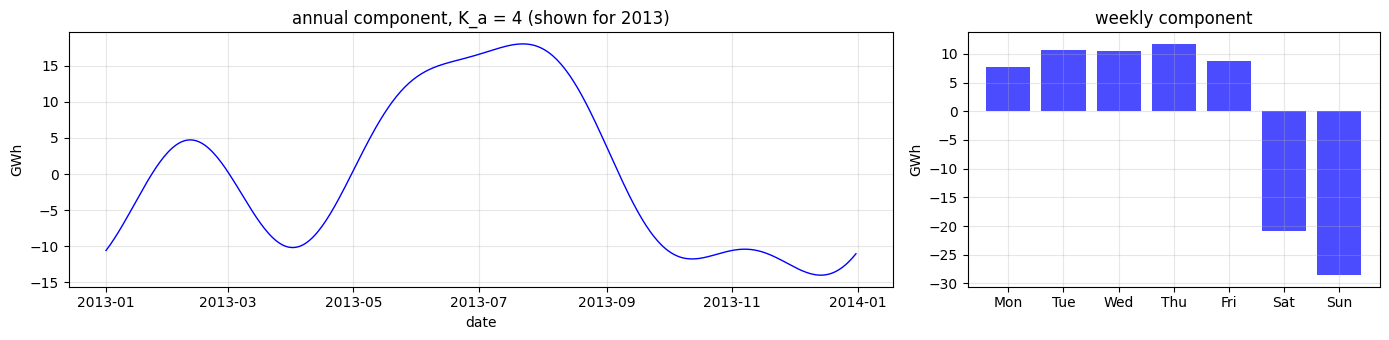

In [13]:
annual_part = X_elec.filter(regex=r"^a(sin|cos)") @ fit_elec.params.filter(regex=r"^a(sin|cos)")
weekly_part = X_elec.filter(regex=r"^w(sin|cos)") @ fit_elec.params.filter(regex=r"^w(sin|cos)")
week = weekly_part.groupby(weekly_part.index.dayofweek).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={"width_ratios": [2, 1]})
run_sequence_plot(annual_part["2013"], title=f"annual component, K_a = {K_a} (shown for 2013)",
                  xlabel="date", ylabel="GWh", ax=axes[0])
axes[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], week, color="blue", alpha=0.7)
axes[1].set(title="weekly component", ylabel="GWh"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

After the temperature effects, the annual component still varies by about 30 GWh: it is highest in the winter months June to August and lowest from October to January, with a smaller peak in February. These are the seasonal effects that temperature does not explain, such as daylight hours and school and work holidays (Chapter 8). The weekly component is the working week: Tuesday to Thursday highest, Monday and Friday slightly lower, Saturday about 30 GWh below the weekdays and Sunday lowest. Now the residuals, with up to two weeks of lags.

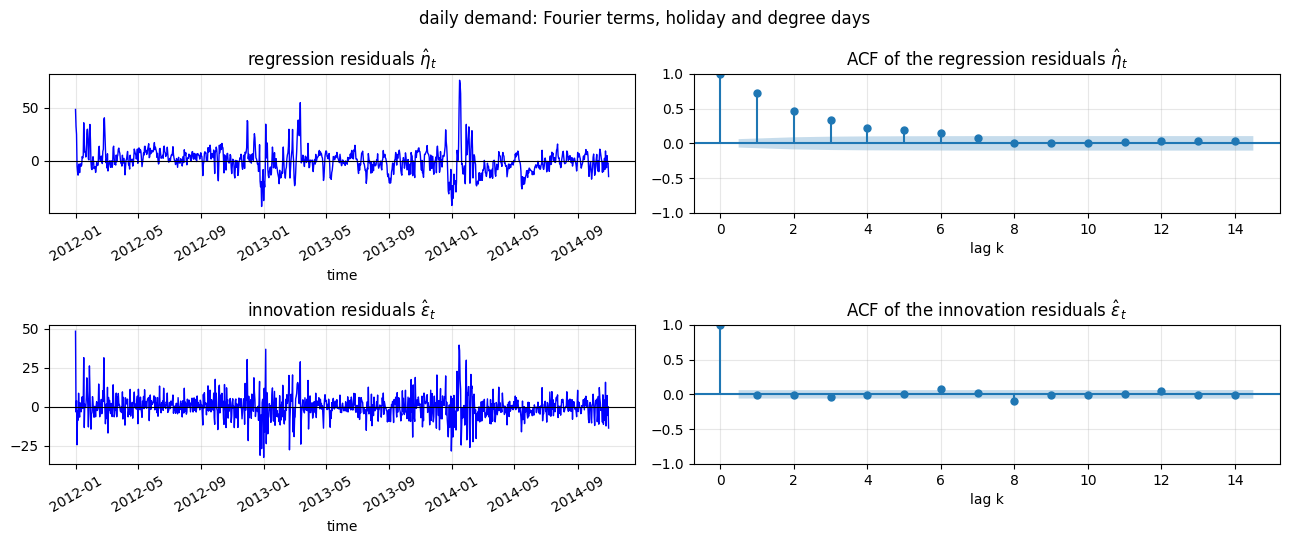

Ljung-Box, regression residuals (lag 14, model_df = 0): Q = 1017.31, p = 3.02e-208
Ljung-Box, innovation residuals (lag 14, model_df = 3): Q = 23.14, p = 0.0169


In [14]:
residual_check(fit_elec, d_train, X_train, lags=14, title="daily demand: Fourier terms, holiday and degree days")

The regression residuals are what the OLS regression of Chapter 8 left behind: demand today resembles demand yesterday beyond what the calendar and temperature explain, with an autocorrelation of about 0.7 at lag 1. The ARMA(2,1) errors absorb almost all of it. The Ljung-Box test still rejects at the 5% level, but the remaining autocorrelations are all small, below about 0.1 in size: with more than a thousand observations, even small correlations are significant.

### What do the ARMA errors add to the forecasts?

On the test months, we compare **one-step-ahead** forecasts: each day, demand is forecast from the data up to the day before, with the parameters estimated on the training data. `fit.apply(...)` runs the fitted model, with its parameters fixed, over the whole series. Both models use the observed temperatures of the test days, so these are ex-post forecasts (Chapter 8).

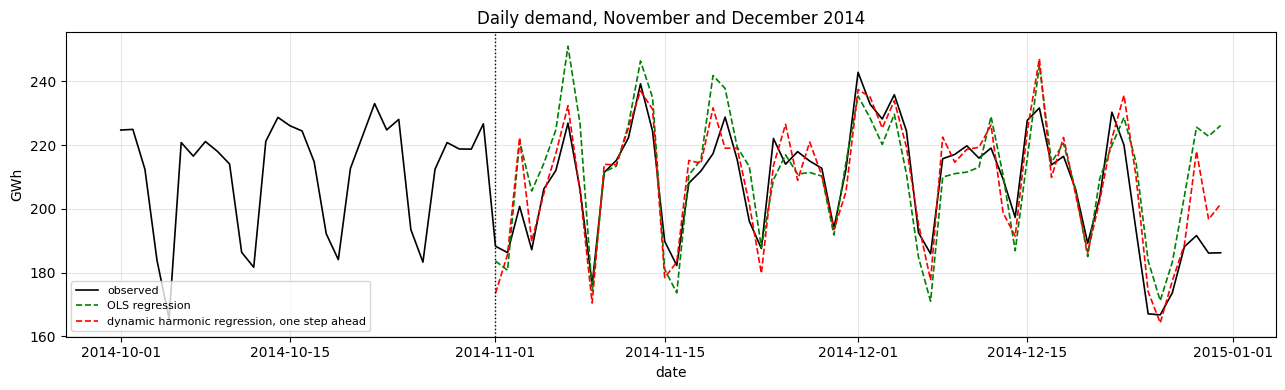

test RMSE, OLS regression                          : 13.06 GWh
test RMSE, dynamic regression, one step ahead      :  8.38 GWh
test RMSE, dynamic regression, all from 31 October : 12.52 GWh


In [15]:
onestep = fit_elec.apply(demand, exog=X_elec).predict(start=elec_test)       # parameters stay fixed
ols_pred = ols_elec.predict(sm.add_constant(X_test, has_constant="add"))
multistep = fit_elec.get_forecast(len(d_test), exog=X_test).predicted_mean   # all 61 days from 31 October

_, ax = plt.subplots(figsize=(13, 4))
ax.plot(demand["2014-10-01":], color="black", lw=1.2, label="observed")
ax.plot(ols_pred, color="green", lw=1.2, ls="--", label="OLS regression")
ax.plot(onestep, color="red", lw=1.2, ls="--", label="dynamic harmonic regression, one step ahead")
ax.axvline(d_test.index[0], color="black", ls=":", lw=1)
ax.set(title="Daily demand, November and December 2014", xlabel="date", ylabel="GWh")
ax.grid(alpha=0.3); ax.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

print(f"test RMSE, OLS regression                          : {np.sqrt(mse(d_test, ols_pred)):5.2f} GWh")
print(f"test RMSE, dynamic regression, one step ahead      : {np.sqrt(mse(d_test, onestep)):5.2f} GWh")
print(f"test RMSE, dynamic regression, all from 31 October : {np.sqrt(mse(d_test, multistep)):5.2f} GWh")

One day ahead, the dynamic regression cuts the RMSE by more than a third: when demand is above the regression today, it is likely to be above it tomorrow, and the ARMA errors use that. Forecasting all 61 days from 31 October, the advantage disappears: the forecast of the ARMA part decays to zero within a few days, and the dynamic regression then forecasts like a plain regression. The ARMA errors improve the forecasts at short horizons, and give correct prediction intervals at all horizons; the long-run forecast comes from the regression part.

The largest errors of both models come in the last days of December, up to 40 GWh for OLS on 31 December. The Christmas to New Year shutdown is a recurring dip that neither the holiday dummy nor four smooth annual Fourier pairs capture.

---

# Lagged predictors

Sometimes the impact of a predictor is not simple and immediate. An advertising campaign may affect sales for some time after the end of the campaign, so that sales in one month depend on the advertising expenditure of each of the past few months. Similarly, a change in a company's safety policy may reduce accidents immediately, but have a diminishing effect over time as employees become familiar with the new working conditions and take less care.

In such cases, we include lagged values of the predictor. With a single predictor $x_t$, the model is

$$y_t = \beta_0 + \gamma_0 x_t + \gamma_1 x_{t-1} + \dots + \gamma_k x_{t-k} + \eta_t ,$$

where $\eta_t$ is an ARIMA process. The coefficient $\gamma_j$ is the effect on $y$ of a change in $x$ that happened $j$ periods earlier, and the sum $\gamma_0 + \gamma_1 + \dots + \gamma_k$ is the total effect of a permanent one-unit increase in $x$. The number of lags $k$ can be selected by AICc, together with the orders $p$ and $q$ of the ARIMA errors.

## Example: TV advertising and insurance quotations

A US insurance company advertises on television to increase the number of insurance quotations it provides, and thereby the number of new policies. The file `data/insurance.csv` holds the number of quotations and the TV advertising expenditure for each month from January 2002 to April 2005.

40 months, Jan 2002 - Apr 2005


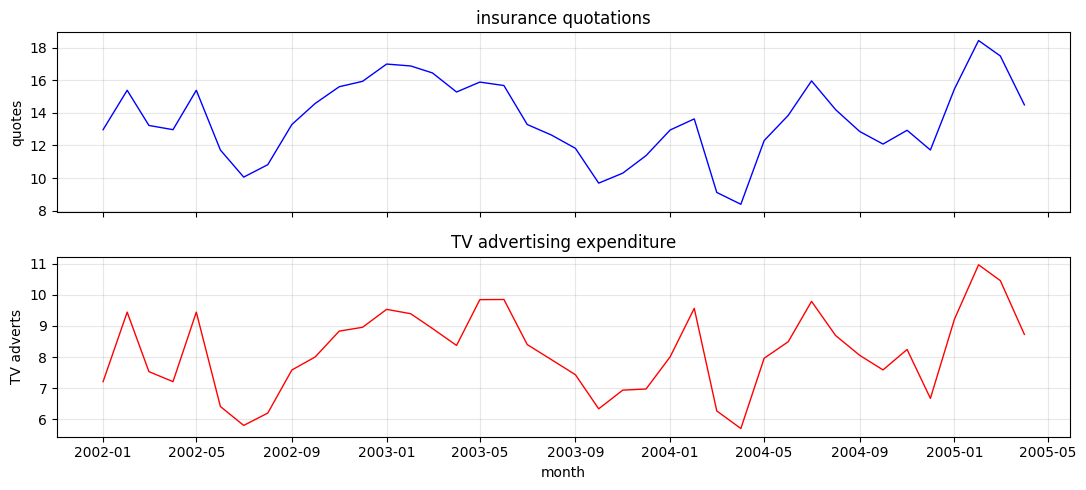

In [16]:
ins = pd.read_csv("data/insurance.csv", parse_dates=["ds"], index_col="ds")[["Quotes", "TVadverts"]].asfreq("MS")
print(f"{len(ins)} months, {ins.index[0]:%b %Y} - {ins.index[-1]:%b %Y}")

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
run_sequence_plot(ins["Quotes"], title="insurance quotations", xlabel="", ylabel="quotes", ax=axes[0])
run_sequence_plot(ins["TVadverts"], title="TV advertising expenditure", xlabel="month", ylabel="TV adverts",
                  ax=axes[1], color="red")
plt.tight_layout(); plt.show()

The two series move together closely. Both look stationary, and the ADF test agrees, so the errors need no differencing ($d = 0$). The cross-correlation function of Chapter 9, $\mathrm{CCF}(k) = \mathrm{corr}(\text{Quotes}_t, \text{TVadverts}_{t-k})$, shows at which lags advertising is related to quotations.

ADF p-value, Quotes   : 0.0102
ADF p-value, TVadverts: 0.0005


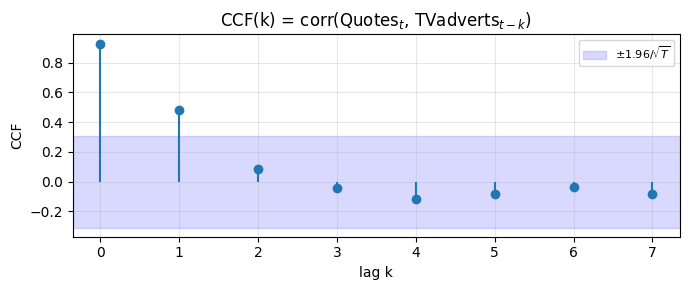

CCF at lags 0-3: [ 0.93  0.49  0.08 -0.04]


In [17]:
for col in ins:
    print(f"ADF p-value, {col:9s}: {adfuller(ins[col])[1]:.4f}")

ccf_vals = ccf(ins["Quotes"], ins["TVadverts"], adjusted=False, nlags=8)
_, ax = plt.subplots(figsize=(7, 3))
ax.stem(np.arange(len(ccf_vals)), ccf_vals, basefmt=" ")
ax.axhspan(-1.96 / np.sqrt(len(ins)), 1.96 / np.sqrt(len(ins)), color="blue", alpha=0.15, label=r"$\pm 1.96/\sqrt{T}$")
ax.set(title=r"CCF(k) = corr(Quotes$_t$, TVadverts$_{t-k}$)", xlabel="lag k", ylabel="CCF")
ax.legend(loc="upper right", fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("CCF at lags 0-3:", ccf_vals[:4].round(2))

The correlation is 0.93 in the same month and 0.49 one month later; from lag 2 on it is negligible. The CCF is only a first look: advertising is itself autocorrelated, so part of the correlation at lag 1 may simply reflect the effect in the same month. We let the dynamic regression decide, with up to three lags: advertising in the current month and in the three months before.

**Compare the models on the same observations.** The model with three lags cannot be fitted to the first three months, which have no $x_{t-3}$. AICc depends on the number of observations, so every model must use the same ones: we drop the first three months for all of them. For each number of lags, `select_arma` chooses the ARMA errors with $p, q \le 2$, enough for 37 observations.

In [18]:
ins_lags = ins.assign(**{f"TVadverts_{k}": ins["TVadverts"].shift(k) for k in (1, 2, 3)})
lag_cols = ["TVadverts", "TVadverts_1", "TVadverts_2", "TVadverts_3"]
same_obs = ins_lags.iloc[3:]                         # the 37 months for which all lags exist

start = time.perf_counter()
rows = {}
for k in range(4):
    best = select_arma(same_obs["Quotes"], exog=same_obs[lag_cols[:k + 1]], d=0, trend="c").iloc[0]
    rows[f"lags 0-{k}"] = {"predictors": ", ".join(lag_cols[:k + 1]), "ARMA errors": best["order"],
                           "AICc": best["AICc"]}
print(f"time required: {time.perf_counter() - start:.0f} s")
pd.DataFrame(rows).T.astype({"AICc": float}).round(2)

time required: 5 s


,predictors,ARMA errors,AICc
lags 0-0,TVadverts,"(2, 0, 0)",68.50
lags 0-1,"TVadverts, TVadverts_1","(1, 0, 1)",61.91
lags 0-2,"TVadverts, TVadverts_1, TVadverts_2","(1, 0, 1)",63.26
lags 0-3,"TVadverts, TVadverts_1, TVadverts_2, TVadverts_3","(1, 0, 1)",65.46


The best model, with the smallest AICc, includes advertising in the current month and in the previous month only. Adding the second and third lags makes AICc worse, and leaving out the first lag is clearly worse.

We now re-estimate the model with lags 0 and 1 on all the data that it can use: only the first month is lost. With two more observations, AICc selects slightly different ARMA errors.

In [19]:
use = ins_lags.iloc[1:]                              # x_{t-1} exists from the second month on
X_ins = use[["TVadverts", "TVadverts_1"]]
print(select_arma(use["Quotes"], exog=X_ins, d=0, trend="c").head(3).round(2).to_string(), "\n")

fit_ins = ARIMA(use["Quotes"], exog=X_ins, order=(1, 0, 2), trend="c").fit()
print(fit_ins.summary().tables[1])

       order    AIC   AICc    BIC
0  (1, 0, 2)  61.88  65.49  73.52
1  (1, 0, 1)  62.98  65.60  72.96
2  (0, 0, 2)  64.08  66.71  74.07 

                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           2.1558      0.965      2.233      0.026       0.264       4.048
TVadverts       1.2526      0.072     17.515      0.000       1.112       1.393
TVadverts_1     0.1464      0.067      2.195      0.028       0.016       0.277
ar.L1           0.5123      0.269      1.902      0.057      -0.016       1.040
ma.L1           0.9169      0.192      4.768      0.000       0.540       1.294
ma.L2           0.4592      0.160      2.872      0.004       0.146       0.773
sigma2          0.1888      0.067      2.809      0.005       0.057       0.321


The selected model has ARIMA(1,0,2) errors:

$$y_t = 2.156 + 1.253\,x_t + 0.146\,x_{t-1} + \eta_t, \qquad \eta_t = 0.512\,\eta_{t-1} + \varepsilon_t + 0.917\,\varepsilon_{t-1} + 0.459\,\varepsilon_{t-2},$$

where $y_t$ is the number of quotations in month $t$, $x_t$ the advertising expenditure in month $t$, and $\varepsilon_t$ white noise. One more unit of advertising brings 1.25 more quotations in the same month and 0.15 the month after: a total effect of 1.40. The lagged effect is small but significant at the 5% level.

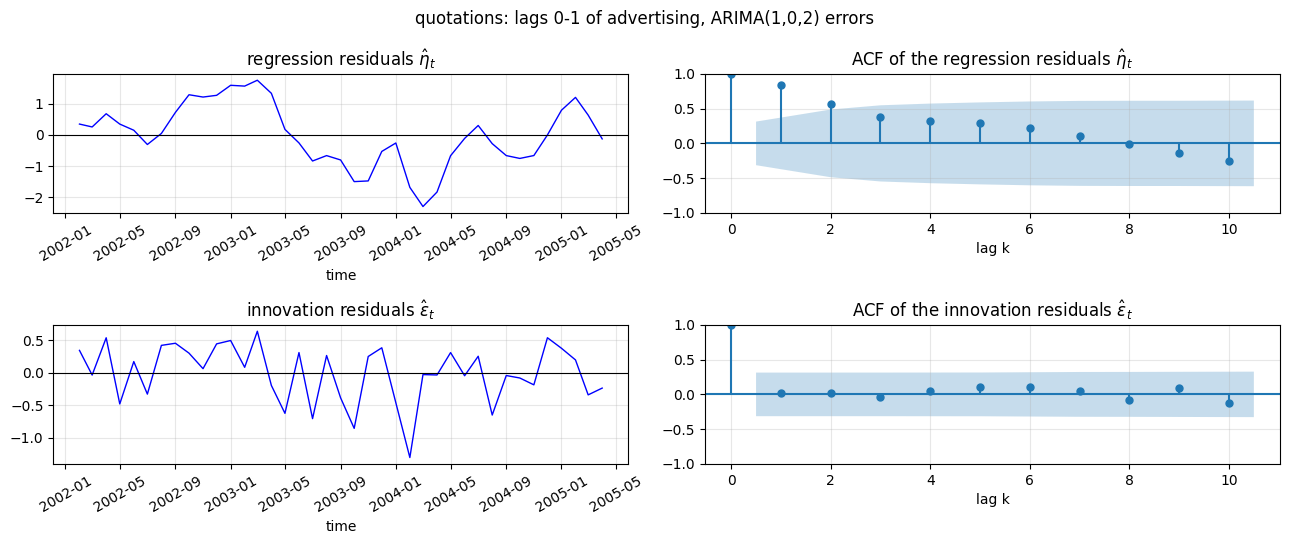

Ljung-Box, regression residuals (lag 10, model_df = 0): Q = 65.58, p = 3.13e-10
Ljung-Box, innovation residuals (lag 10, model_df = 3): Q = 2.94, p = 0.891


In [20]:
residual_check(fit_ins, use["Quotes"], X_ins, lags=10, title="quotations: lags 0-1 of advertising, ARIMA(1,0,2) errors")

The regression residuals swing in waves that last several months, with an autocorrelation above 0.8 at lag 1, and the Ljung-Box test rejects white noise clearly. The ARIMA(1,0,2) errors absorb this: the innovation residuals pass the test.

### Forecasting with assumed advertising

To forecast, we need future values of the advertising expenditure. The company decides them, so a scenario forecast (Chapter 8) is natural: we set the advertising to 8 units in each of the next 12 months. The lagged predictor for the first forecast month, May 2005, is the last observed advertising value, April's 8.73; only from June on does it take the assumed value. We add two more scenarios, 6 and 10 units a month.

advertising = 10: forecasts 15.52, 15.81, 15.98, ..., 16.15;  long-run level 16.15
advertising =  8: forecasts 13.02, 13.02, 13.18, ..., 13.35;  long-run level 13.35
advertising =  6: forecasts 10.51, 10.22, 10.38, ..., 10.55;  long-run level 10.55


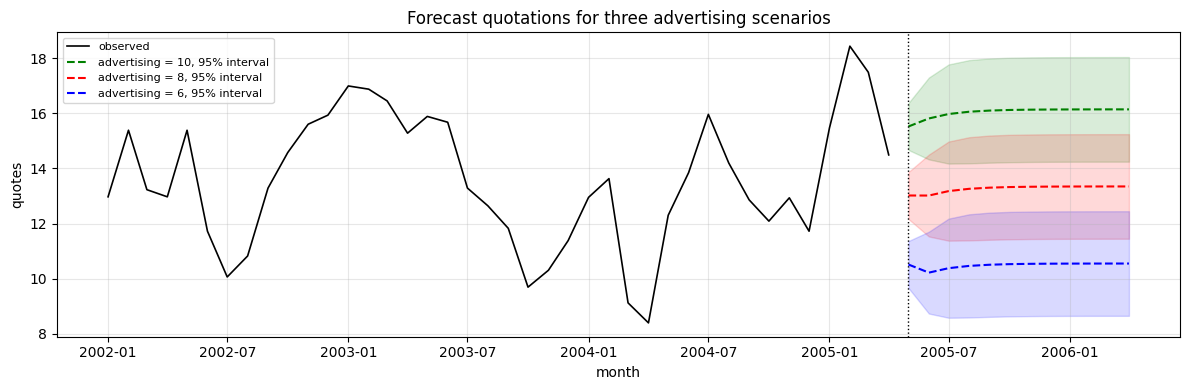

In [21]:
H = 12
idx_future = pd.date_range(ins.index[-1] + pd.DateOffset(months=1), periods=H, freq="MS")


def advertising_scenario(level):
    "Future predictors for a constant advertising level; x_{t-1} starts from the last observed value."
    future = pd.DataFrame({"TVadverts": float(level)}, index=idx_future)
    future["TVadverts_1"] = future["TVadverts"].shift(1, fill_value=ins["TVadverts"].iloc[-1])
    return future


_, ax = plt.subplots(figsize=(12, 4))
ax.plot(ins["Quotes"], color="black", lw=1.2, label="observed")
for level, color in [(10, "green"), (8, "red"), (6, "blue")]:
    pred = forecast_with_interval(ax, fit_ins, H, idx_future, exog=advertising_scenario(level), color=color,
                                  label=f"advertising = {level}, 95% interval")
    long_run = fit_ins.params["const"] + (fit_ins.params["TVadverts"] + fit_ins.params["TVadverts_1"]) * level
    print(f"advertising = {level:2d}: forecasts {pred[0]:.2f}, {pred[1]:.2f}, {pred[2]:.2f}, ..., {pred[-1]:.2f};"
          f"  long-run level {long_run:.2f}")
ax.axvline(idx_future[0], color="black", ls=":", lw=1)
ax.set(title="Forecast quotations for three advertising scenarios", xlabel="month", ylabel="quotes")
ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

In each scenario, the forecasts move within a few months to the long-run level $\hat\beta_0 + (\hat\gamma_0 + \hat\gamma_1)\,x$, as the forecast of the ARMA part decays: 13.35 quotations a month with 8 units of advertising, 2.8 more or fewer for two units more or less. The first forecast month is pulled towards the current state by the ARMA errors and by April's advertising, which still acts through $x_{t-1}$.

As always with scenarios, the prediction intervals are conditional on the assumed advertising: they contain no uncertainty about the predictor. Here that is not a weakness, since the company sets its own advertising budget.

---

# Summary

**Dynamic harmonic regression**: $\ y_t = \beta_0 + \sum_{k=1}^{K}\bigl[\alpha_k \sin(2\pi k t / m) + \gamma_k \cos(2\pi k t / m)\bigr] + \text{other predictors} + \eta_t$, with $\eta_t$ ARMA, or ARIMA if the series needs differencing.

- Use it for **long or non-integer seasonal periods** (daily, weekly, sub-daily data), where seasonal dummies, Holt-Winters and SARIMA need too many parameters, states or data. A SARIMA model with $s = 365$ has 732 states and spends a year of data on the seasonal difference.
- Several seasonal periods: add Fourier pairs of each period. $K$ controls the smoothness; $K = m/2$ is equivalent to seasonal dummies.
- Choose $d$ with a KPSS test on the OLS residuals, then $K$ and the ARMA order by AICc (the same $d$ and data for all candidates), and check on held-out data.
- The seasonal pattern is fixed over time. The ARMA errors improve short-horizon forecasts and make the prediction intervals and standard errors honest; long-horizon forecasts come from the regression part.

**Lagged predictors**: $\ y_t = \beta_0 + \gamma_0 x_t + \gamma_1 x_{t-1} + \dots + \gamma_k x_{t-k} + \eta_t$.

- Build the lags with `shift`; compare lag lengths by AICc **on the same observations**, then refit the chosen model on all usable data.
- $\gamma_0 + \dots + \gamma_k$ is the total effect of a permanent change in $x$. To forecast, the first lags come from the last observed values of $x$, the later ones from the assumed future values.

**What we learned**

1. **Eating-out expenditure** (monthly, logs): AICc fell as $K$ grew and chose $K = 5$ with ARIMA(0,1,1) errors and a drift of about 5% a year. With more Fourier pairs, the ARMA errors became simpler. On 2017-2018, $K = 4$ to 6 were practically equal, with a MAPE of 2.3% to 2.5%, half the error of seasonal naive.
2. **Daily electricity demand** (weekly and annual cycles): four annual and three weekly Fourier pairs, a holiday dummy and degree days, with ARMA(2,1) errors, removed most of the autocorrelation that the OLS regression of Chapter 8 left behind, and cut the one-day-ahead RMSE by more than a third. The OLS estimates of the temperature and holiday effects were larger and, for the holiday and cooling effects, only half as precise.
3. **Insurance quotations**: advertising acts in the current month and the next (lags 0 and 1, total effect 1.40 quotations per unit). Scenario forecasts converge to $\hat\beta_0 + 1.40\,x$ within a few months.